# ms.annotation.magma

下面的单元格读取真实冻结模型运行结果，重新核算并绘图；它们不等于再次运行模型。来源文件和哈希可追溯到原始推理，不使用假想预测。

In [1]:
import json, sys, io
from pathlib import Path
from IPython.display import display, Markdown, SVG
root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'openmolspec_bench').is_dir()), None)
if root is None:
    raise RuntimeError('Run from the cloned release repository; see Quick Start')
sys.path.insert(0, str(root / 'scripts'))
from documentation_evidence import load_evidence, compact, recompute, render
from documentation_content import results_table
evidence = load_evidence('ms.annotation.magma')
print(json.dumps({'task': evidence['task'], 'status': evidence['status'], 'source_sha256': evidence['source_hashes']}, indent=2, ensure_ascii=False))

{
  "task": "ms.annotation.magma",
  "status": "recorded_results",
  "source_sha256": {
    "magma_real_test_verified_20261115.json": "e65563b00863389105f5eae392d493167d693ac4ca38b9f1abfbd40942d1946b"
  }
}


## 实际输入与输出

使用记录中的第一例。超过八项的数组会显示长度和缩略值，完整数值保存在可下载证据 JSON 中。

In [2]:
example = evidence['examples'][0]
print(json.dumps(compact(example), indent=2, ensure_ascii=False))

{
  "input": {
    "smiles": "C1=CC=C(C(=C1)C2=CC=C(C=C2)C(=O)O)C3=NNN=N3",
    "adduct": "[M+H]+",
    "observed_peaks": {
      "length": 40,
      "first_values": [
        [
          86.0158,
          0.14814814814814814
        ],
        [
          87.0237,
          0.16016016016016016
        ],
        [
          97.0082,
          0.06906906906906907
        ],
        [
          98.0159,
          1.0
        ],
        [
          99.0096,
          0.05305305305305305
        ],
        [
          99.0229,
          0.3783783783783784
        ],
        [
          100.0176,
          0.02002002002002002
        ],
        [
          100.0303,
          0.08208208208208208
        ]
      ]
    }
  },
  "sample_id": "MassSpecGymID0046618",
  "output": {
    "engine_smiles": "O=C(O)c1ccc(-c2ccccc2-c2nn[nH]n2)cc1",
    "peak_annotations": {
      "length": 40,
      "first_values": [
        {
          "peak_id": 7,
          "mz": 86.0158,
          "intensity": 0.1

## 实际运行指标与重新核算

In [3]:
display(Markdown(results_table(evidence, False)))
print(json.dumps(recompute(evidence), indent=2, ensure_ascii=False))

| Dataset / scope | Model / variant | Metric | Value |
| --- | --- | --- | ---: |
| recorded evaluation | recorded model | matched_peak_fraction | 0.568182 |
| recorded evaluation | recorded model | checked_fragments | 1534 |


{
  "scope": "Saved model outputs are shown directly; aggregate metrics are in the run table.",
  "recorded_runs": 1,
  "real_examples": 2
}


## 预测／参考对照图

这是算法标注，不是可微调神经模型；应改进匹配和验证。

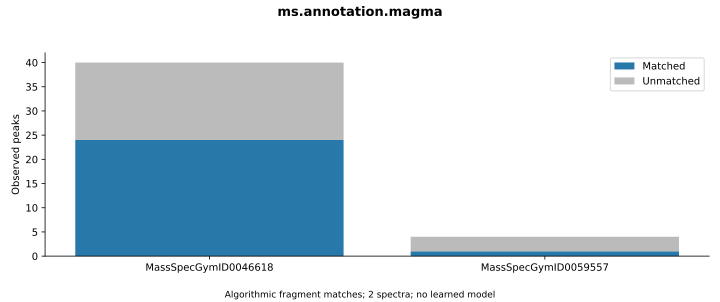

In [4]:
figure = render('ms.annotation.magma', evidence)
image = io.StringIO()
figure.savefig(image, format='svg', metadata={'Date': None})
display(SVG(image.getvalue()))
import matplotlib.pyplot as plt
plt.close(figure)

## 重新执行模型

按任务页面与 Quick Start 配置原模型运行环境、checkpoint 和数据。上面的分析单元格只需要文档示例环境。

[Task](../tasks/ms-annotation-magma.md) · [Quick Start](../quickstart.md)
